# **VAE and Diffusion Models on MNIST and Fashion-MNIST**

**Stefano Meza Anzules**

## Introduction

This notebook extends the unconditional DDPM with class conditioning and classifier-free guidance. Using the same MNIST and Fashion-MNIST splits, it trains class-conditional diffusion models, examines their learning curves, and generates samples for requested digit and clothing categories.

## 1. Setup

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import MNIST, FashionMNIST
from torchvision.transforms import ToTensor
from IPython.display import display

cwd = Path.cwd().resolve()
ROOT = next((p for p in [cwd, *cwd.parents]
             if (p / "src/conditional_diffusion.py").is_file() and (p / "data/splits").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Run this notebook from the project root or notebooks/ directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.conditional_diffusion import ConditionalDDPM, ConditionalNoiseUNet
from src.conditional_training import fit_conditional, load_conditional
from src.training import set_seed

SEED = 111
set_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Device: cuda
NVIDIA GeForce RTX 3050 Laptop GPU


/home/stefano98/miniconda3/envs/vae-diffusion/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Experiment settings

A short smoke test first checks whether training, checkpoint saving, and sampling work. The smoke test uses fewer images and epochs, so its samples are not meant to look good. For the full comparison, `SMOKE_TEST` is set to `False` to train on the complete training split.

The `RUN_TAG` keeps these experiments separate from the unconditional DDPM checkpoints.

In [2]:
SMOKE_TEST = False
REUSE_COMPLETED = True
RUN_TAG = "conditional_v1"
DATASET_NAMES = ["mnist", "fashion_mnist"]
BATCH_SIZE = 64
NUM_WORKERS = 0
BASE_CHANNELS = 32
TIMESTEPS = 300
LEARNING_RATE = 1e-3
DROP_PROB = 0.1
GUIDANCE_SCALE = 2.0
EPOCHS = 2 if SMOKE_TEST else 30
MODE = "smoke" if SMOKE_TEST else "full"

CLASS_NAMES = {
    "mnist": [str(i) for i in range(10)],
    "fashion_mnist": ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
                      "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
}
FIG_DIR = ROOT / "results/figures/conditional_diffusion" / f"{RUN_TAG}_{MODE}"
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 3. Load the saved splits

The training and validation indices from the earlier notebooks are reused. The class labels are already part of the torchvision datasets, so no additional annotation file is needed. Images are loaded in $[0,1]$ and converted to $[-1,1]$ inside the training loop.

In [3]:
data = {}
for name in DATASET_NAMES:
    dataset_class = {"mnist": MNIST, "fashion_mnist": FashionMNIST}[name]
    dataset = dataset_class(ROOT / "data/raw", train=True, download=False, transform=ToTensor())
    split_path = ROOT / "data/splits" / f"{name}_seed{SEED}.npz"
    with np.load(split_path, allow_pickle=False) as saved:
        train_idx, val_idx = saved["train_idx"].copy(), saved["val_idx"].copy()
    assert len(train_idx) == 50000 and len(val_idx) == 10000
    if SMOKE_TEST:
        rng = np.random.default_rng(SEED)
        train_idx = rng.choice(train_idx, 2048, replace=False)
        val_idx = rng.choice(val_idx, 512, replace=False)
    data[name] = (dataset, train_idx, val_idx)
    print(f"{name}: {len(train_idx):,} training / {len(val_idx):,} validation")

def make_loaders(name):
    dataset, train_idx, val_idx = data[name]
    train_loader = DataLoader(Subset(dataset, train_idx.tolist()), batch_size=BATCH_SIZE,
        shuffle=True, num_workers=NUM_WORKERS,
        generator=torch.Generator().manual_seed(SEED), pin_memory=device.type == "cuda")
    val_loader = DataLoader(Subset(dataset, val_idx.tolist()), batch_size=BATCH_SIZE,
        shuffle=False, num_workers=NUM_WORKERS, pin_memory=device.type == "cuda")
    return train_loader, val_loader

mnist: 50,000 training / 10,000 validation
fashion_mnist: 50,000 training / 10,000 validation


## 4. Class conditioning and classifier-free guidance

The unconditional model predicts noise from the noisy image and timestep. This model also receives a class label, $y$:

$$\epsilon_\theta(x_t,t,y).$$

Each label is represented by a learned embedding and added to the timestep embedding. During training, 10% of labels are replaced with a special *null* label. This teaches the same network to make predictions both with and without class information.

At sampling time, the two predictions are combined:

$$\hat\epsilon=\epsilon_{\mathrm{uncond}}+w(\epsilon_{\mathrm{cond}}-\epsilon_{\mathrm{uncond}}).$$

Here $w$ is the guidance scale. At $w=1$, sampling uses the conditional prediction directly. Larger values emphasize the class signal, although they can also affect image quality.

In [4]:
model = ConditionalNoiseUNet(base_channels=BASE_CHANNELS).to(device)
process = ConditionalDDPM(timesteps=TIMESTEPS).to(device)
x = torch.randn(4, 1, 28, 28, device=device)
t = torch.tensor([0, 50, 150, TIMESTEPS - 1], device=device)
labels = torch.tensor([0, 3, 7, 9], device=device)
with torch.no_grad():
    prediction = model(x, t, labels)
    loss = process.loss(model, x, labels, drop_prob=DROP_PROB)
print("Prediction shape:", tuple(prediction.shape))
print("Initial loss:", float(loss))
assert prediction.shape == x.shape and torch.isfinite(loss)

Prediction shape: (4, 1, 28, 28)
Initial loss: 1.0213345289230347


## 5. Train the conditional models

One model is trained for each dataset. The training objective is still the mean squared error between the sampled noise and the predicted noise; the difference is that the U-Net now receives a class label as well.

The best validation checkpoint is saved and reused when the corresponding experiment is already complete. The validation noise is seeded consistently each epoch, and smoke-test checkpoints are kept separate from full runs.

In [5]:
runs = {}
for name in DATASET_NAMES:
    run_id = f"{name}_{RUN_TAG}_{MODE}"
    checkpoint_dir = ROOT / "results/checkpoints/conditional_diffusion" / run_id
    metric_dir = ROOT / "results/metrics/conditional_diffusion" / run_id
    config = dict(run_id=run_id, dataset=name, seed=SEED, timesteps=TIMESTEPS,
                  base_channels=BASE_CHANNELS, batch_size=BATCH_SIZE,
                  learning_rate=LEARNING_RATE, epochs=EPOCHS,
                  drop_prob=DROP_PROB, mode=MODE)
    best_path = checkpoint_dir / "best.pt"
    if REUSE_COMPLETED and best_path.exists() and (metric_dir / "summary.json").exists():
        old_config = json.loads((metric_dir / "config.json").read_text())
        if old_config != config:
            raise ValueError(f"Existing configuration differs for {run_id}; change RUN_TAG")
        trained_model, trained_process, saved = load_conditional(best_path, device)
        history = pd.read_csv(metric_dir / "history.csv")
        summary = json.loads((metric_dir / "summary.json").read_text())
        print(f"Loaded {run_id} (best epoch {summary['best_epoch']})")
    else:
        set_seed(SEED)
        train_loader, val_loader = make_loaders(name)
        trained_model = ConditionalNoiseUNet(base_channels=BASE_CHANNELS)
        trained_process = ConditionalDDPM(timesteps=TIMESTEPS)
        history, summary = fit_conditional(trained_model, trained_process,
            train_loader, val_loader, device, config, checkpoint_dir, metric_dir)
        trained_model, trained_process, saved = load_conditional(best_path, device)
    runs[name] = dict(model=trained_model, process=trained_process,
                      history=history, summary=summary)

display(pd.DataFrame([{"dataset": name, **r["summary"]} for name, r in runs.items()]))

mnist_conditional_v1_full:   3%|▎         | 1/30 [00:17<08:34, 17.74s/it]

Epoch 01: train=0.0761, val=0.0535


mnist_conditional_v1_full:   7%|▋         | 2/30 [00:34<08:05, 17.35s/it]

Epoch 02: train=0.0503, val=0.0495


mnist_conditional_v1_full:  10%|█         | 3/30 [00:51<07:45, 17.25s/it]

...

fashion_mnist_conditional_v1_full:  97%|█████████▋| 29/30 [08:19<00:17, 17.25s/it]

Epoch 29: train=0.0697, val=0.0706


fashion_mnist_conditional_v1_full: 100%|██████████| 30/30 [08:36<00:00, 17.23s/it]

Epoch 30: train=0.0697, val=0.0703


,dataset,best_epoch,best_val_loss,parameter_count
0,mnist,30,0.039531,268769
1,fashion_mnist,28,0.070276,268769


## 6. Training curves

Loss curves are plotted to check whether the noise predictor is learning. The MSE is useful for tracking training, but it does not establish whether a generated image matches its requested class.

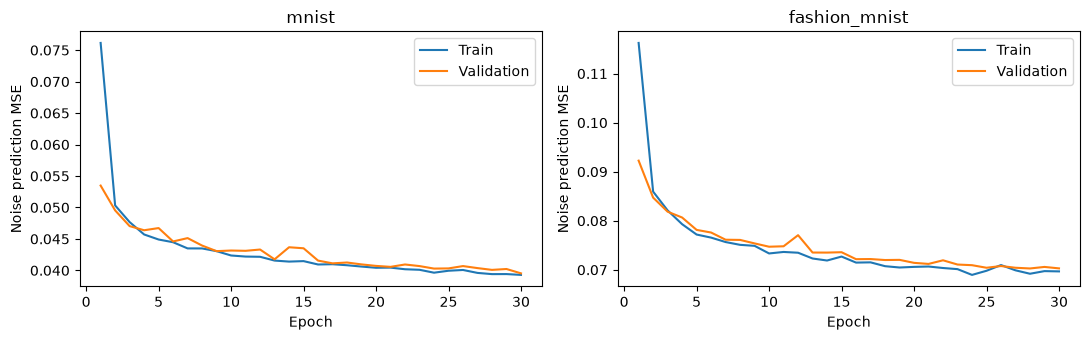

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, (name, run) in zip(axes, runs.items()):
    h = run["history"]
    ax.plot(h["epoch"], h["train_loss"], label="Train")
    ax.plot(h["epoch"], h["val_loss"], label="Validation")
    ax.set(title=name, xlabel="Epoch", ylabel="Noise prediction MSE")
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "training_curves.png", dpi=150)
plt.show()

## 7. Generate a sample from each class

Images are generated using requested labels from 0 through 9. Each column has a known *requested* class, unlike the unconditional DDPM. A requested label does not guarantee a matching generated image, so the outputs are inspected visually.

Sampling takes time because each image needs 300 reverse steps. Sampling starts with one image per class for each dataset.

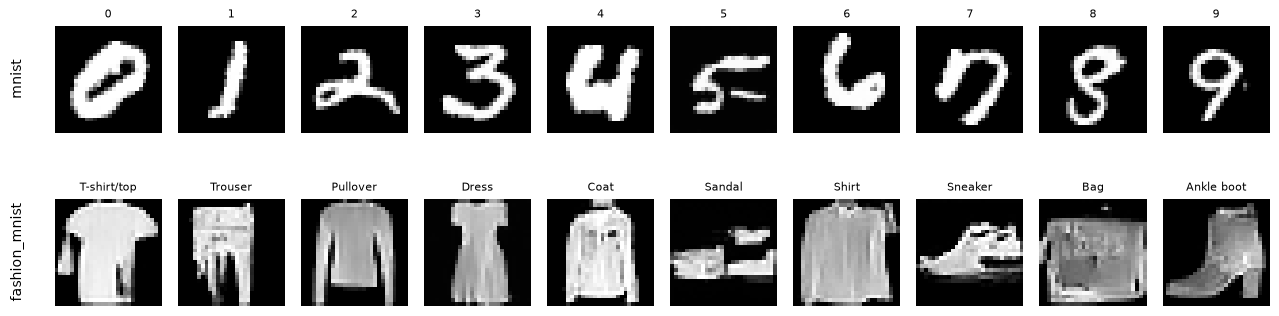

In [7]:
fig, axes = plt.subplots(2, 10, figsize=(15, 3.8))
for row, (name, run) in enumerate(runs.items()):
    set_seed(SEED + 20)
    labels = torch.arange(10, device=device)
    samples = run["process"].sample(run["model"], labels=labels,
        device=device, guidance_scale=GUIDANCE_SCALE).cpu()
    for col, ax in enumerate(axes[row]):
        ax.imshow(samples[col, 0], cmap="gray", vmin=0, vmax=1)
        ax.set_title(CLASS_NAMES[name][col], fontsize=8)
        ax.axis("off")
    axes[row, 0].text(-0.35, 0.5, name, rotation=90,
        transform=axes[row, 0].transAxes, ha="center", va="center")
plt.subplots_adjust(left=0.09, wspace=0.15, hspace=0.45)
plt.savefig(FIG_DIR / "samples_by_class.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Generate several images of one class

To examine variation within a class, eight images are generated with the same label. The examples use digit 7 and ankle boot (class 9); the selected labels can be changed after training.

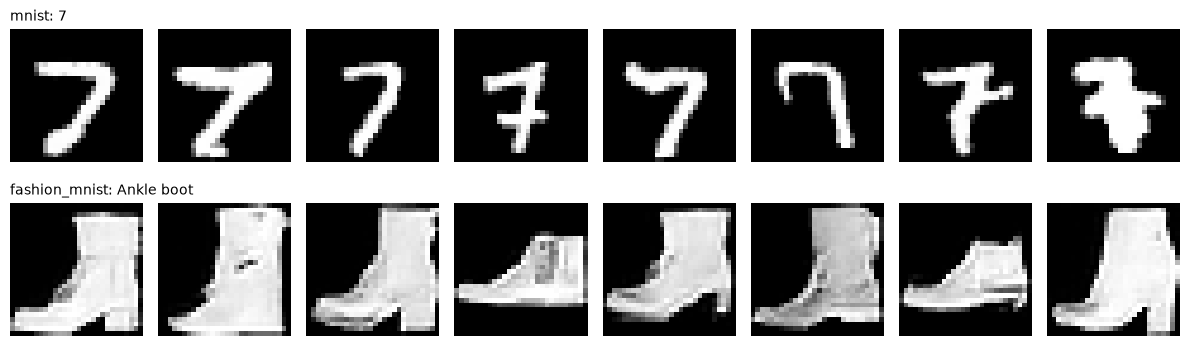

In [8]:
TARGET_CLASSES = {"mnist": 7, "fashion_mnist": 9}
fig, axes = plt.subplots(2, 8, figsize=(12, 3.8))
for row, (name, run) in enumerate(runs.items()):
    target = TARGET_CLASSES[name]
    labels = torch.full((8,), target, device=device, dtype=torch.long)
    set_seed(SEED + 30)
    samples = run["process"].sample(run["model"], labels=labels,
        device=device, guidance_scale=GUIDANCE_SCALE).cpu()
    for col, ax in enumerate(axes[row]):
        ax.imshow(samples[col, 0], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
        if col == 0:
            ax.set_title(f"{name}: {CLASS_NAMES[name][target]}", loc="left", fontsize=10)
plt.tight_layout()
plt.savefig(FIG_DIR / "repeated_class_samples.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Results and discussion

Both conditional diffusion models were trained for 30 epochs. The best validation losses were 0.0395 for MNIST and 0.0703 for Fashion-MNIST.
The training and validation curves follow similar trends, without a large gap between them. Most of the improvement occurs during the first epochs, while the losses decrease more slowly toward the end of training.

Looking at the generated images, the model generally produces samples that correspond to the requested classes. This is particularly clear for MNIST, where most digits are recognizable, although some contain additional strokes or unusual shapes.

Fashion-MNIST is more challenging. Categories such as ankle boots, bags, and dresses are relatively easy to identify, while some clothing classes have less defined shapes.
Generating multiple images from the same class also shows that the model can produce different variations instead of repeating the same output.
Compared with the unconditional models, class conditioning does not substantially change the validation loss. However, it provides additional control over the generation process, allowing a requested image class to be selected.
These results are based on visual inspection. A more systematic evaluation would require generating a larger number of samples and measuring class consistency and image diversity.